In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as ms
import sklearn
from scipy import stats
import glob
%matplotlib inline

print('Done Setup')

Done Setup


# A = data Acquistion 

In [2]:
import pandas as pd
import glob

# List of your 20 company symbols or CSV filenames
tickers = ['NABIL', 'EBL', 'NIMB', 'ADBL', 'NTC', 'NLIC', 'LICN', 'AHPC', 
           'CHCL', 'SHPC', 'GBIME', 'SCB', 'HDL', 'STC', 'NFS', 'CIT', 
           'TPC', 'BBC', 'CZBIL', 'KBL']

# Option A: If your data is in separate CSV files named after the ticker (e.g., 'NABIL.csv')
dfs = []
for ticker in tickers:
    # Read individual CSV file
    df = pd.read_csv(f"{ticker}.csv")
    
    # Add a column to identify the company
    df['Company'] = ticker
    
    # Ensure Date column is in datetime format
    df['published_date'] = pd.to_datetime(df['published_date'])
    
    dfs.append(df)

# Combine all dataframes into a single master dataframe
nepse_data = pd.concat(dfs, ignore_index=True)

# Sort by Date and Company
nepse_date = nepse_data.sort_values(by=['published_date', 'Company']).reset_index(drop=True)

nepse_data.head(10)

,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company
0,2011-05-15,1091.0,1155.0,1112.0,1155.0,NaN,38.0,43057.0,0,NABIL
1,2011-05-16,1155.0,1193.0,1160.0,1193.0,3.29,156.0,183026.0,0,NABIL
2,2011-05-18,1193.0,1172.0,1150.0,1172.0,-1.76,939.0,1087972.0,0,NABIL
3,2011-05-19,1172.0,1194.0,1155.0,1194.0,1.88,490.0,573992.0,0,NABIL
4,2011-05-22,1194.0,1193.0,1178.0,1178.0,-1.34,115.0,135930.0,0,NABIL
5,2011-05-23,1178.0,1189.0,1165.0,1170.0,-0.68,239.0,279927.0,0,NABIL
6,2011-05-24,1170.0,1160.0,1150.0,1150.0,-1.71,282.0,325456.0,0,NABIL
7,2011-05-25,1150.0,1159.0,1100.0,1150.0,0.00,597.0,664216.0,0,NABIL
8,2011-05-26,1150.0,1149.0,1127.0,1149.0,-0.09,127.0,143553.0,0,NABIL
9,2011-05-30,1149.0,1151.0,1140.0,1150.0,0.09,320.0,366010.0,0,NABIL


In [3]:
nepse_data.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
published_date,58535,NaN,NaN,NaN,2019-06-22 03:40:44.506705,1995-07-20 00:00:00,2015-09-30 00:00:00,2020-01-05 00:00:00,2023-08-02 00:00:00,2026-10-16 00:00:00,NaN
open,58535.0,NaN,NaN,NaN,1179.878917,88.0,351.25,650.0,1520.0,13320.0,1323.151653
high,58535.0,NaN,NaN,NaN,1195.629074,0.0,357.45,659.0,1541.0,13780.0,1344.115606
low,58535.0,NaN,NaN,NaN,1162.803993,0.0,345.1,642.0,1500.0,12501.0,1301.734006
close,58535.0,NaN,NaN,NaN,1178.6934,0.0,351.0,650.0,1520.0,13317.0,1321.487762
per_change,58521.0,NaN,NaN,NaN,0.067899,-76.34,-0.96,0.0,0.81,330.48,2.869575
traded_quantity,58535.0,NaN,NaN,NaN,39276.288169,1.0,2370.5,9809.0,34470.5,3546853.0,101533.52665
traded_amount,58535.0,NaN,NaN,NaN,22708908.86715,0.0,2008851.65,7472196.5,21573510.25,1757930386.0,52134083.962664
status,58535.0,NaN,NaN,NaN,-0.085487,-1.0,-1.0,0.0,1.0,1.0,0.762592
Company,58535,20,CHCL,4479,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
nepse_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 58535 entries, 0 to 58534
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   published_date   58535 non-null  datetime64[us]
 1   open             58535 non-null  float64       
 2   high             58535 non-null  float64       
 3   low              58535 non-null  float64       
 4   close            58535 non-null  float64       
 5   per_change       58521 non-null  float64       
 6   traded_quantity  58535 non-null  float64       
 7   traded_amount    58535 non-null  float64       
 8   status           58535 non-null  int64         
 9   Company          58535 non-null  str           
dtypes: datetime64[us](1), float64(7), int64(1), str(1)
memory usage: 4.5 MB


## null values

In [5]:
nepse_data.isna().sum()

published_date      0
open                0
high                0
low                 0
close               0
per_change         14
traded_quantity     0
traded_amount       0
status              0
Company             0
dtype: int64

### null valeues discription
- per_change = NaN, meaning the company has just started

### null graph

<Axes: >

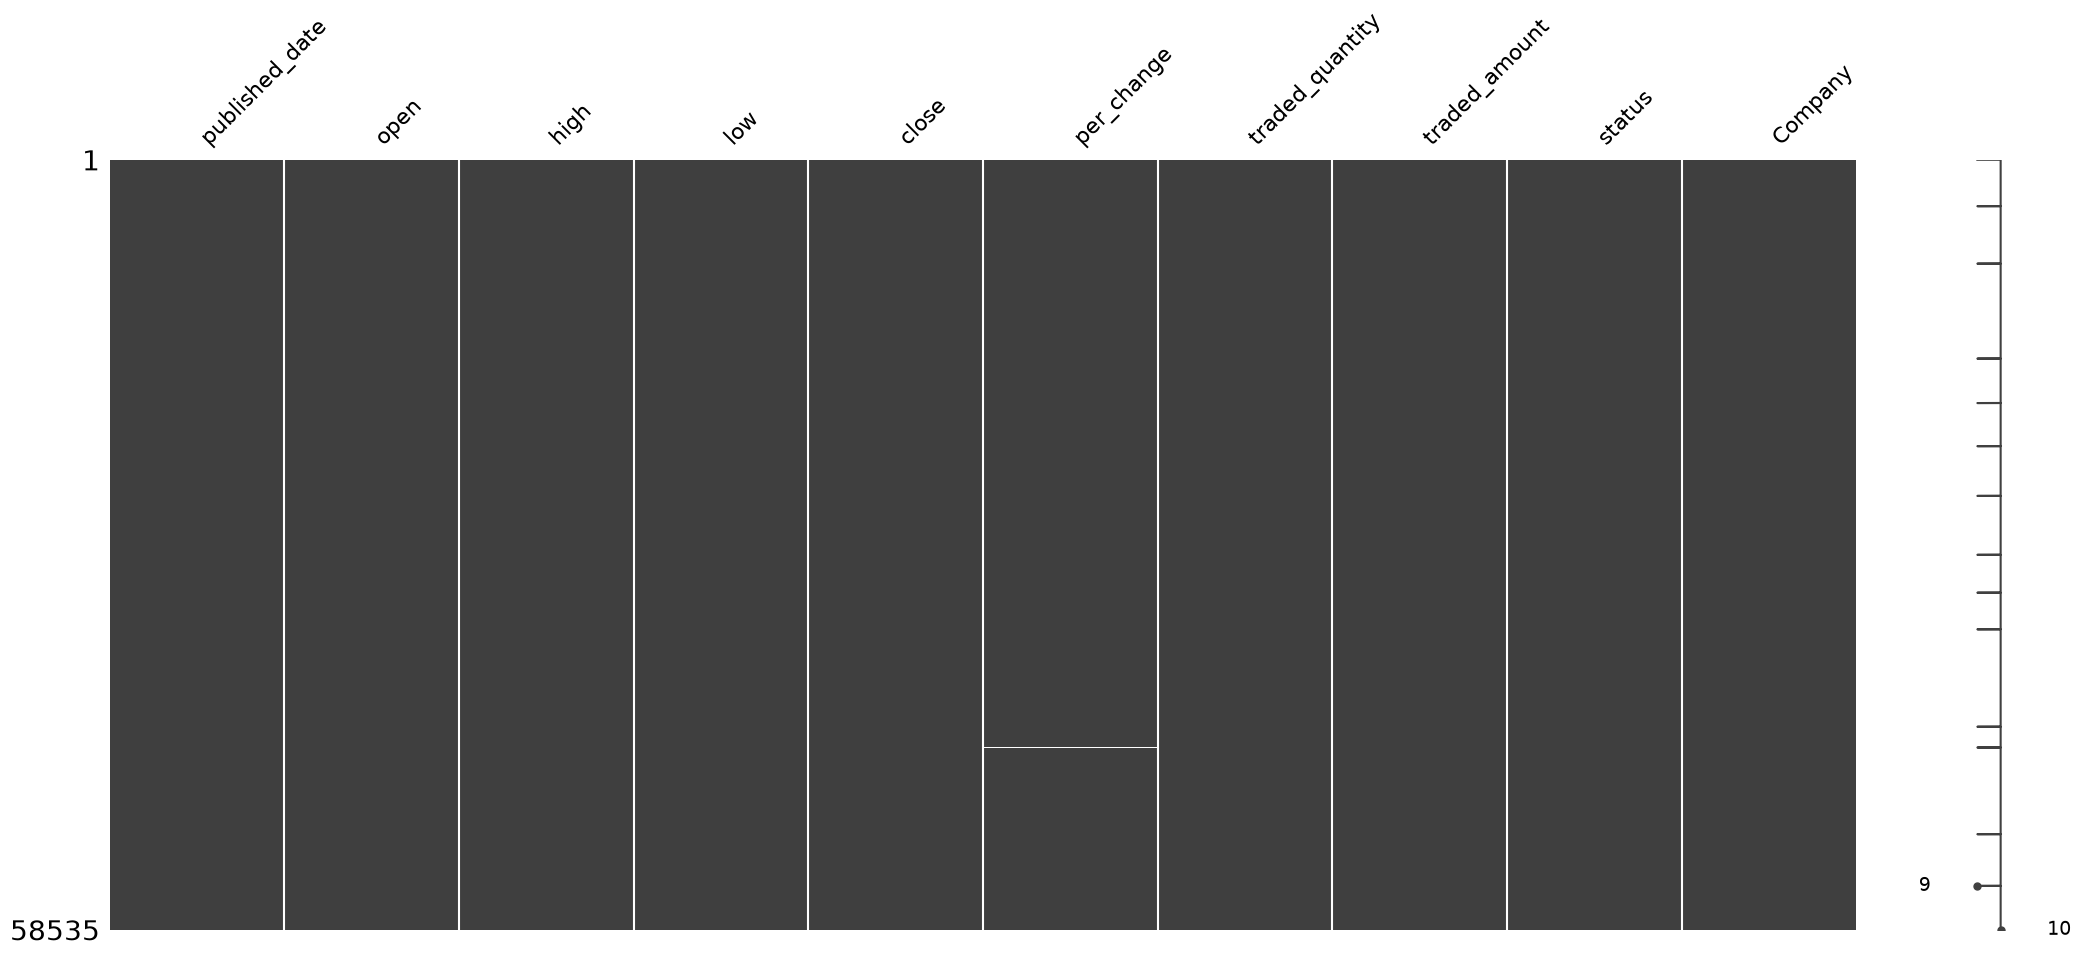

In [6]:
ms.matrix(nepse_data)

In [7]:
nepse_data.shape

(58535, 10)

# F = Data Filter

## company data fiter

In [8]:
nepse_data['Company'].value_counts()

Company
CHCL     4479
CZBIL    3929
AHPC     3779
ADBL     3679
NTC      3539
NABIL    3529
EBL      3529
SCB      3529
NLIC     3379
KBL      3337
LICN     3279
CIT      3079
SHPC     2879
GBIME    2785
BBC      2386
HDL      2249
STC      1627
NFS      1579
TPC      1126
NIMB      838
Name: count, dtype: int64

### pie-chart

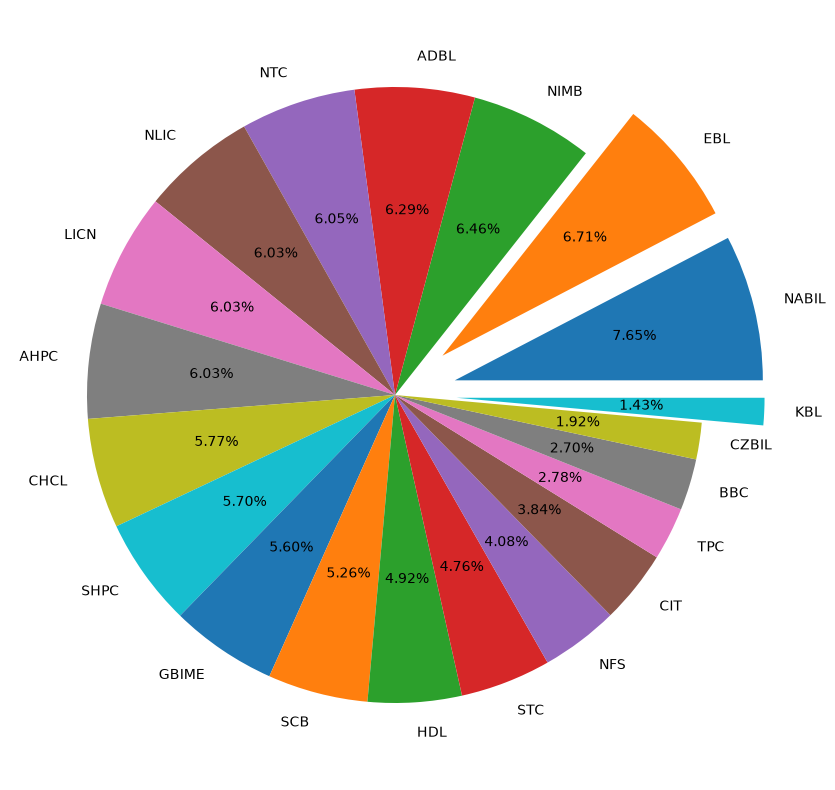

In [9]:
# pie-chatt
plt.figure(figsize = (10, 10))
explode = [0.2,0.2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.2]
plt.pie(nepse_data['Company'].value_counts(), autopct='%1.2f%%', labels=tickers, explode= explode)
plt.show()

### bar graphy traded amount

In [10]:
nepse_data.groupby('Company')['traded_amount'].sum()

Company
ADBL     4.198486e+10
AHPC     1.092338e+11
BBC      5.384256e+09
CHCL     6.757345e+10
CIT      6.428358e+10
CZBIL    4.565516e+10
EBL      7.923509e+10
GBIME    8.283032e+10
HDL      1.293306e+11
KBL      9.335805e+10
LICN     4.147640e+10
NABIL    1.130294e+11
NFS      4.836118e+10
NIMB     2.442536e+10
NLIC     1.303170e+11
NTC      7.979033e+10
SCB      4.151074e+10
SHPC     9.523768e+10
STC      2.211366e+10
TPC      1.413496e+10
Name: traded_amount, dtype: float64

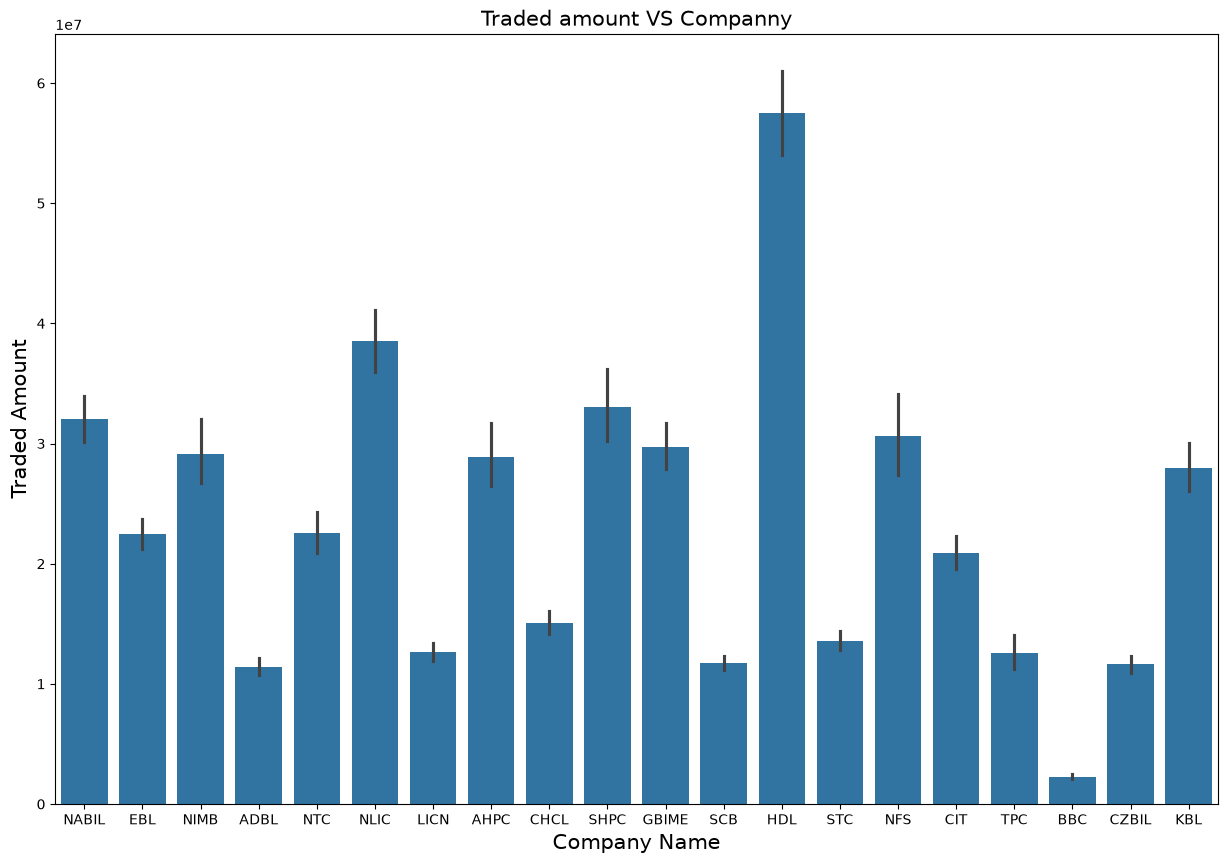

In [11]:
plt.figure(figsize = (15,10))
sns.barplot(data = nepse_data, x = 'Company', y = 'traded_amount' )
plt.xlabel( 'Company Name', fontsize = 15)
plt.ylabel('Traded Amount', fontsize = 15)
plt.title('Traded amount VS Companny', fontsize = 15)
plt.show()

### bar graph for traded quantity

In [12]:
nepse_data.groupby('Company')['traded_quantity'].sum()

Company
ADBL     104994539.0
AHPC     311907437.0
BBC        1306046.0
CHCL     104783612.0
CIT       23197745.0
CZBIL    155188672.0
EBL       92678757.0
GBIME    267867589.0
HDL       62418623.0
KBL      388106166.0
LICN      26253519.0
NABIL    125662746.0
NFS       63006312.0
NIMB     116193556.0
NLIC      99452685.0
NTC       77811554.0
SCB       49810214.0
SHPC     192408738.0
STC        4117334.0
TPC       31871684.0
Name: traded_quantity, dtype: float64

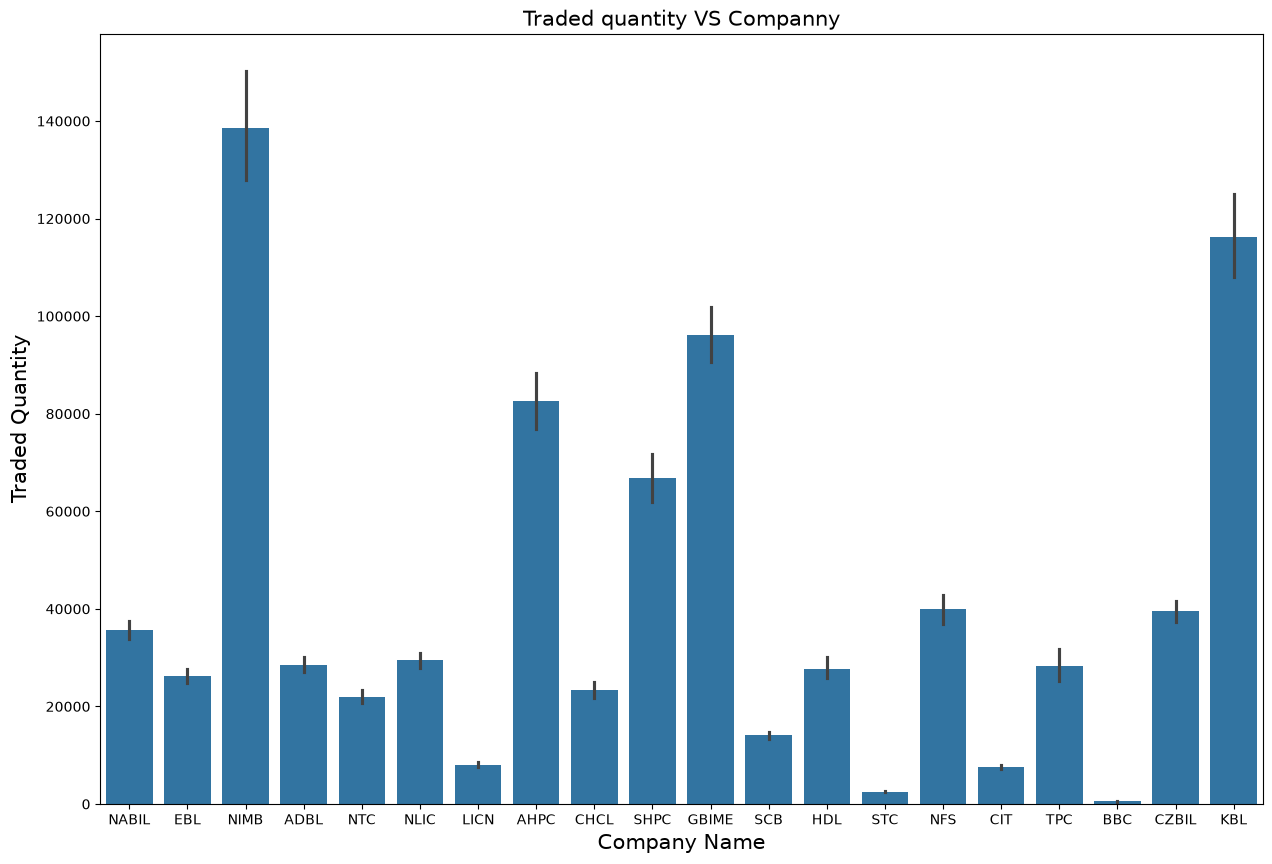

In [13]:
plt.figure(figsize = (15,10))
sns.barplot(data = nepse_data, x = 'Company', y = 'traded_quantity' )
plt.xlabel( 'Company Name', fontsize = 15)
plt.ylabel('Traded Quantity', fontsize = 15)
plt.title('Traded quantity VS Companny', fontsize = 15)
plt.show()

## seperatiing published_date into year month and day


In [14]:
nepse_copy = nepse_data.copy()

nepse_copy['year'] = pd.to_datetime(nepse_copy['published_date']).dt.year
nepse_copy['month'] = pd.to_datetime(nepse_copy['published_date']).dt.month
nepse_copy['day'] = pd.to_datetime(nepse_copy['published_date']).dt.day

nepse_copy.head()

,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day
0,2011-05-15,1091.0,1155.0,1112.0,1155.0,NaN,38.0,43057.0,0,NABIL,2011,5,15
1,2011-05-16,1155.0,1193.0,1160.0,1193.0,3.29,156.0,183026.0,0,NABIL,2011,5,16
2,2011-05-18,1193.0,1172.0,1150.0,1172.0,-1.76,939.0,1087972.0,0,NABIL,2011,5,18
3,2011-05-19,1172.0,1194.0,1155.0,1194.0,1.88,490.0,573992.0,0,NABIL,2011,5,19
4,2011-05-22,1194.0,1193.0,1178.0,1178.0,-1.34,115.0,135930.0,0,NABIL,2011,5,22


### droping column published_date from nepse_copy

In [15]:
nepse_copy.drop(columns = 'published_date', inplace= True)

## Time-Series analysis

### line-graph traded amount by year

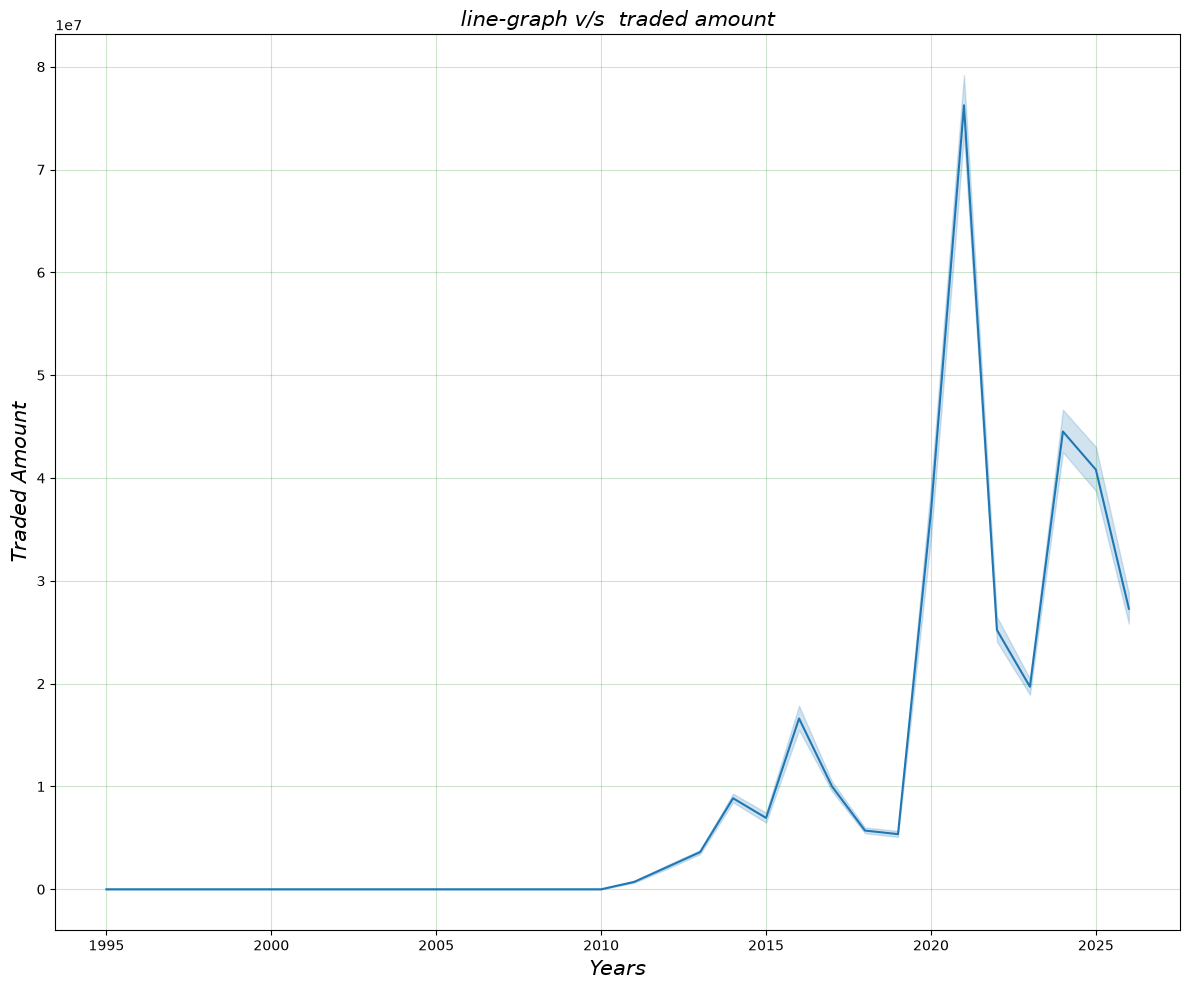

In [16]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'year', y = 'traded_amount')
plt.xlabel('Years', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Amount', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded amount', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

### Line graph for traded quantity

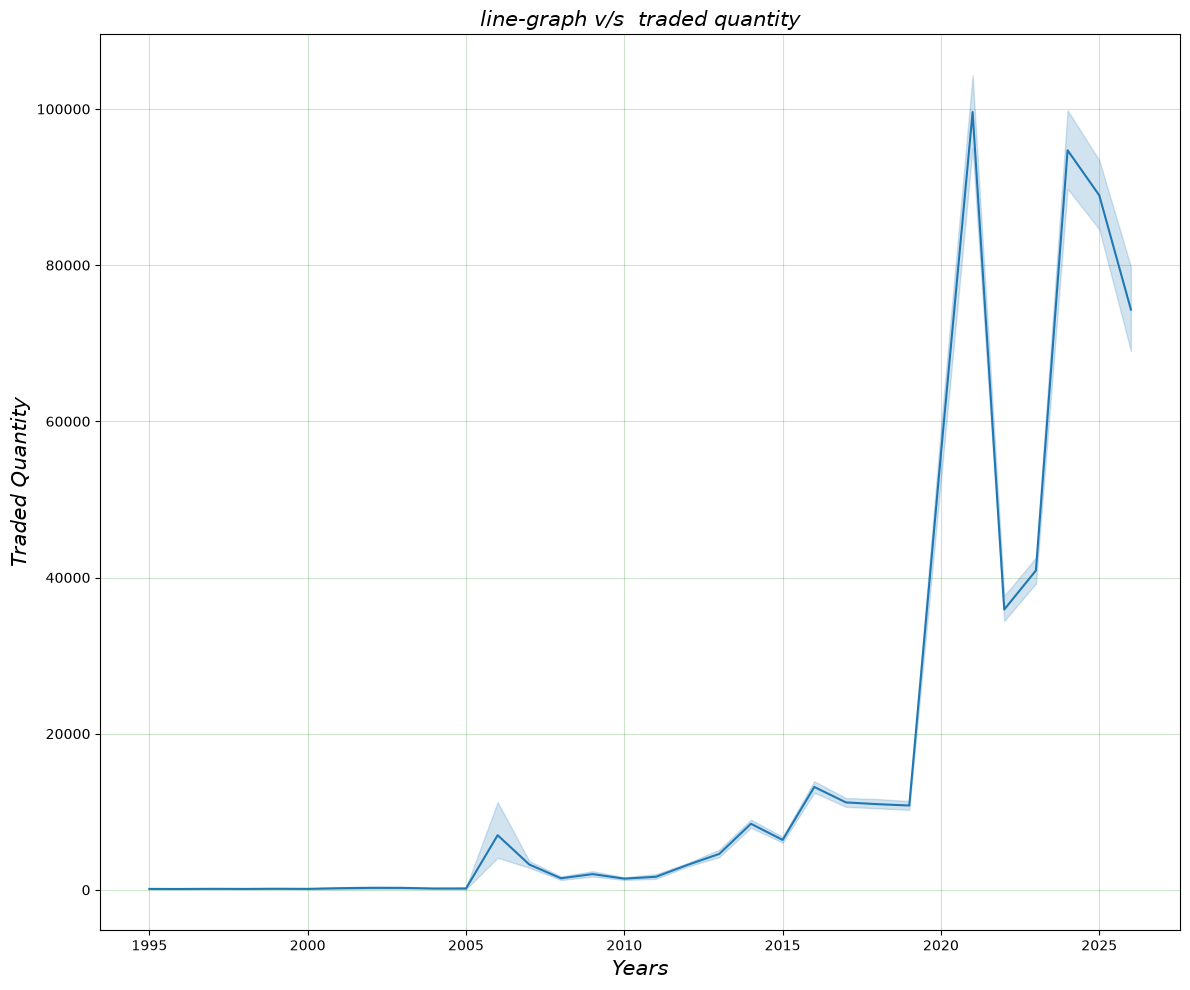

In [17]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'year', y = 'traded_quantity')
plt.xlabel('Years', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Quantity', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded quantity', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

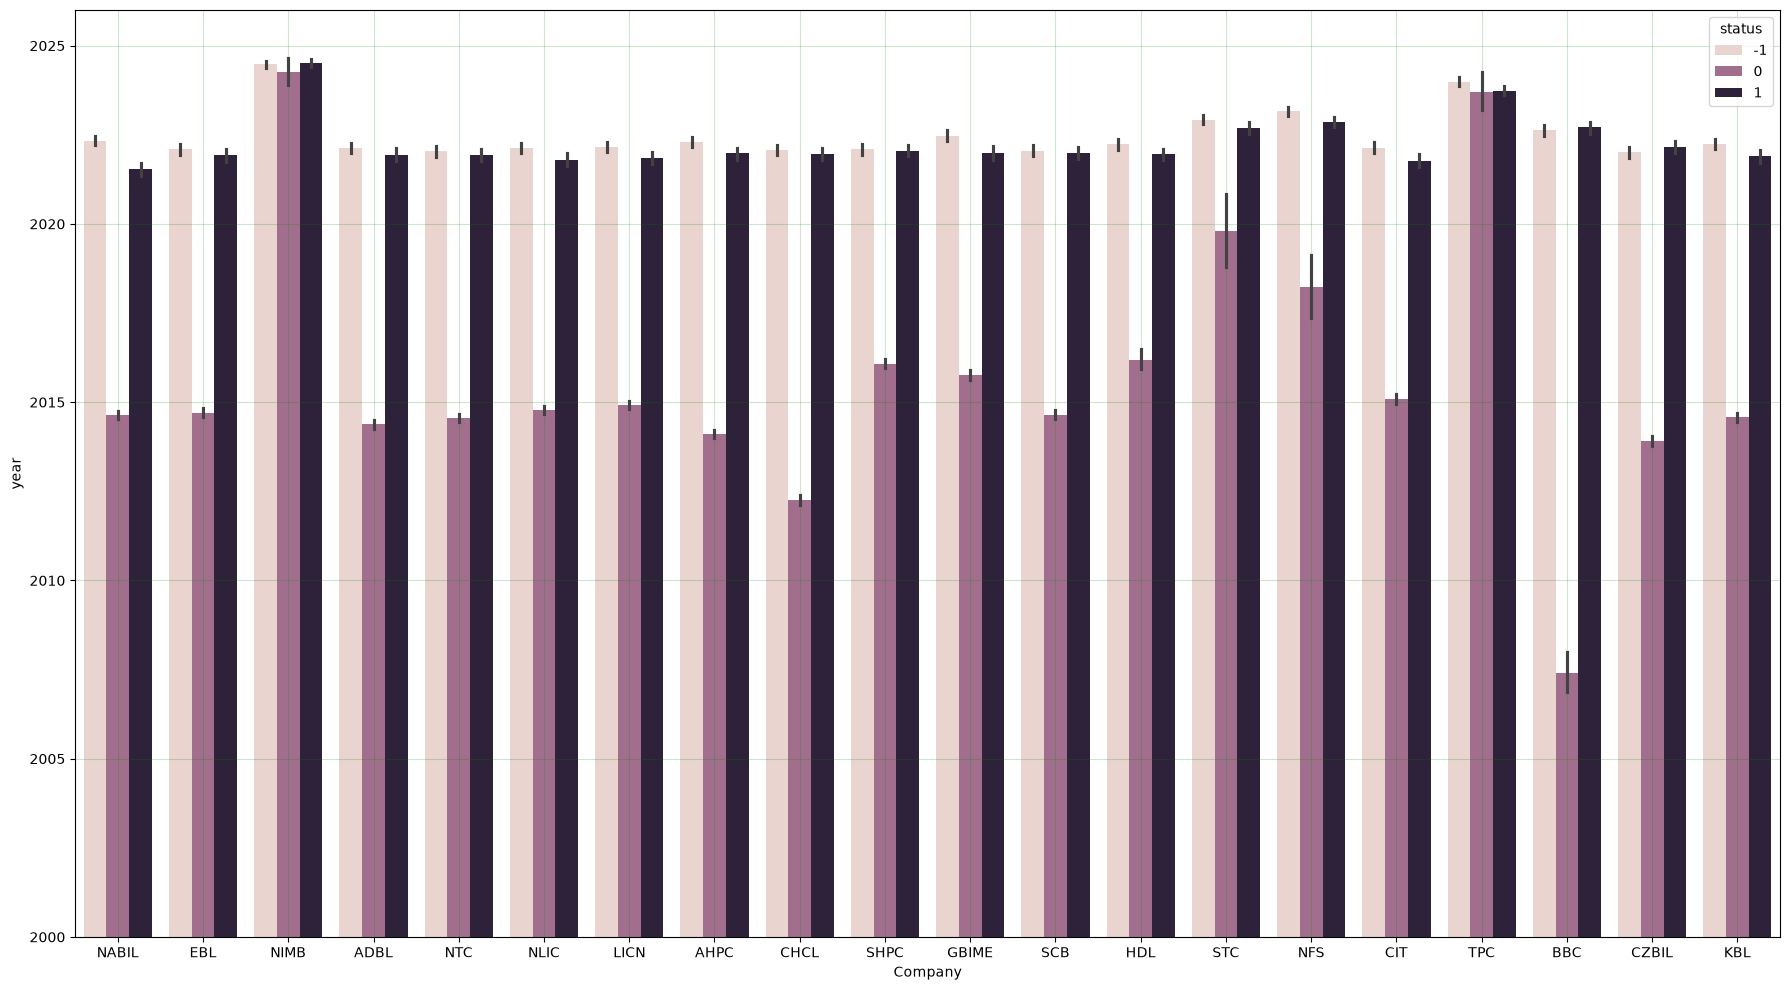

In [18]:
# status
plt.figure(figsize= (18, 10))
sns.barplot(data = nepse_copy, x = 'Company', y = 'year', hue = 'status')
plt.ylim((2000, 2026))
plt.grid(c = 'g', alpha = 0.2)
plt.margins(y = 0.1)
plt.tight_layout()
plt.show()


### Time series by Month

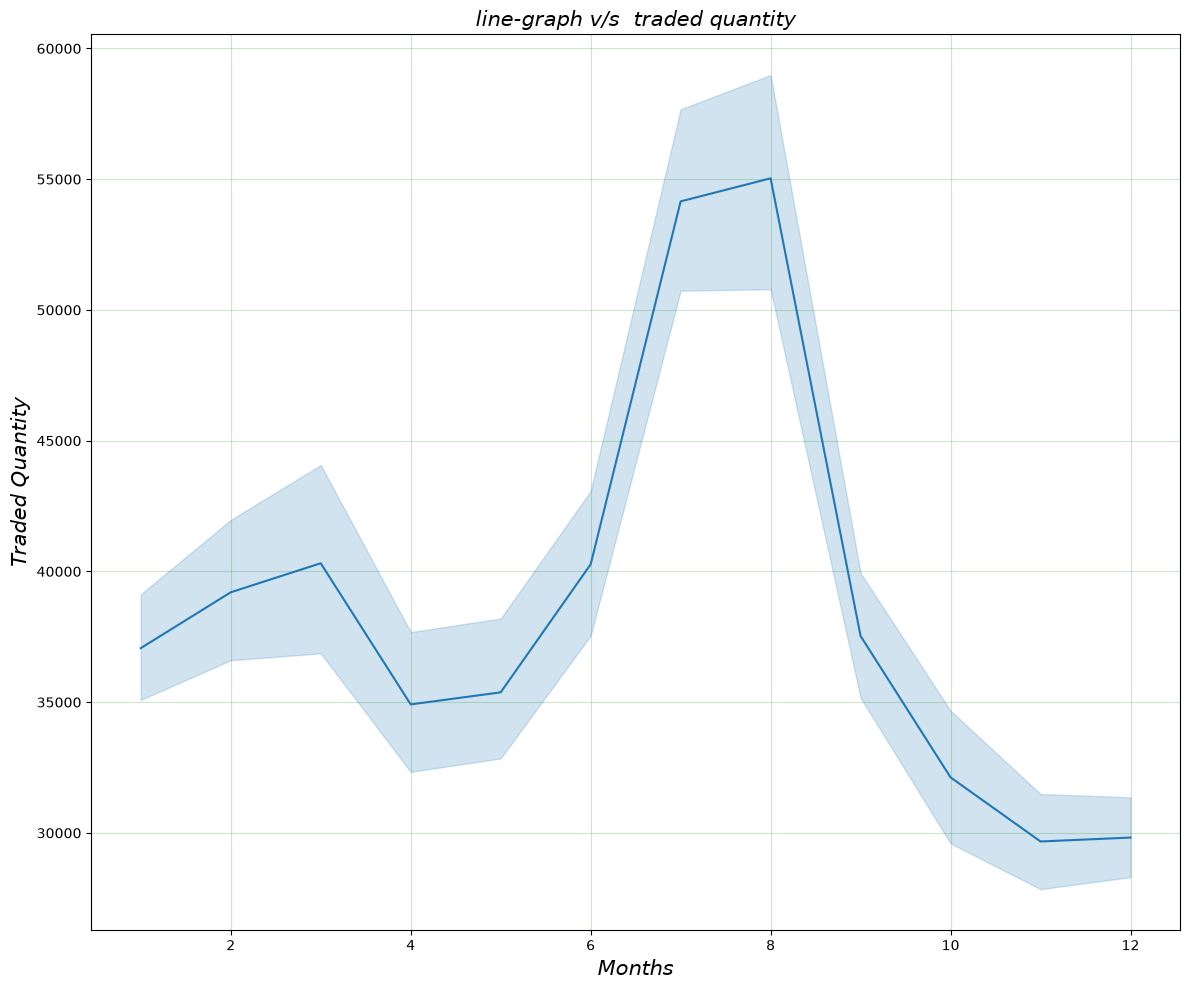

In [20]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'month', y = 'traded_quantity')
plt.xlabel('Months', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Quantity', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded quantity', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

## 2025 opening price

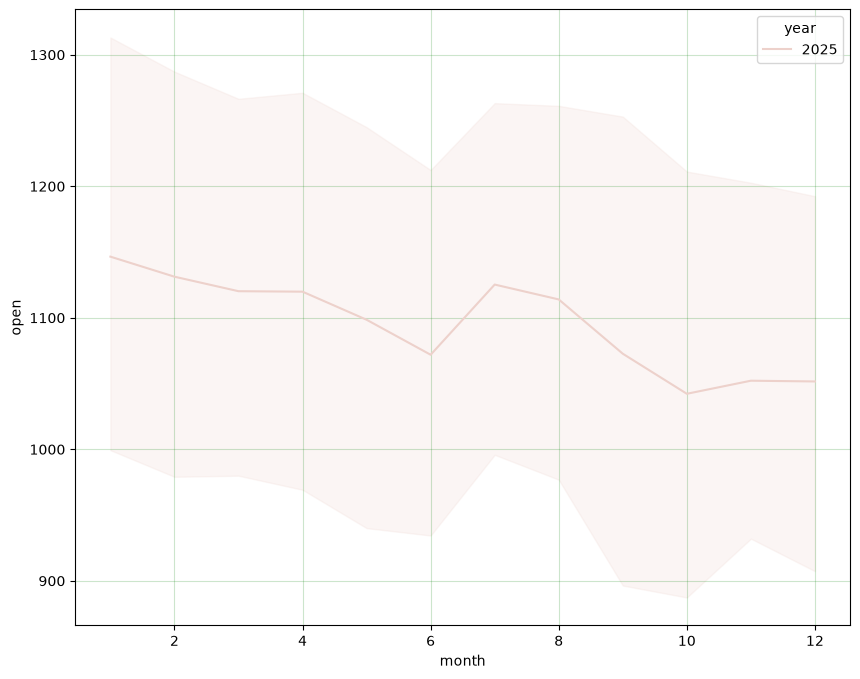

In [35]:
# 1. Filter the DataFrame first for the year 2025
plt.figure(figsize = (10, 8))
filtered_data = nepse_copy[nepse_copy['year'] == 2025]
sns.lineplot(data = filtered_data, x = 'month', y = 'open', hue = 'year')
plt.grid(c ='g', alpha = 0.2)
plt.show()

### 2026 opening vs 2025 opening amount

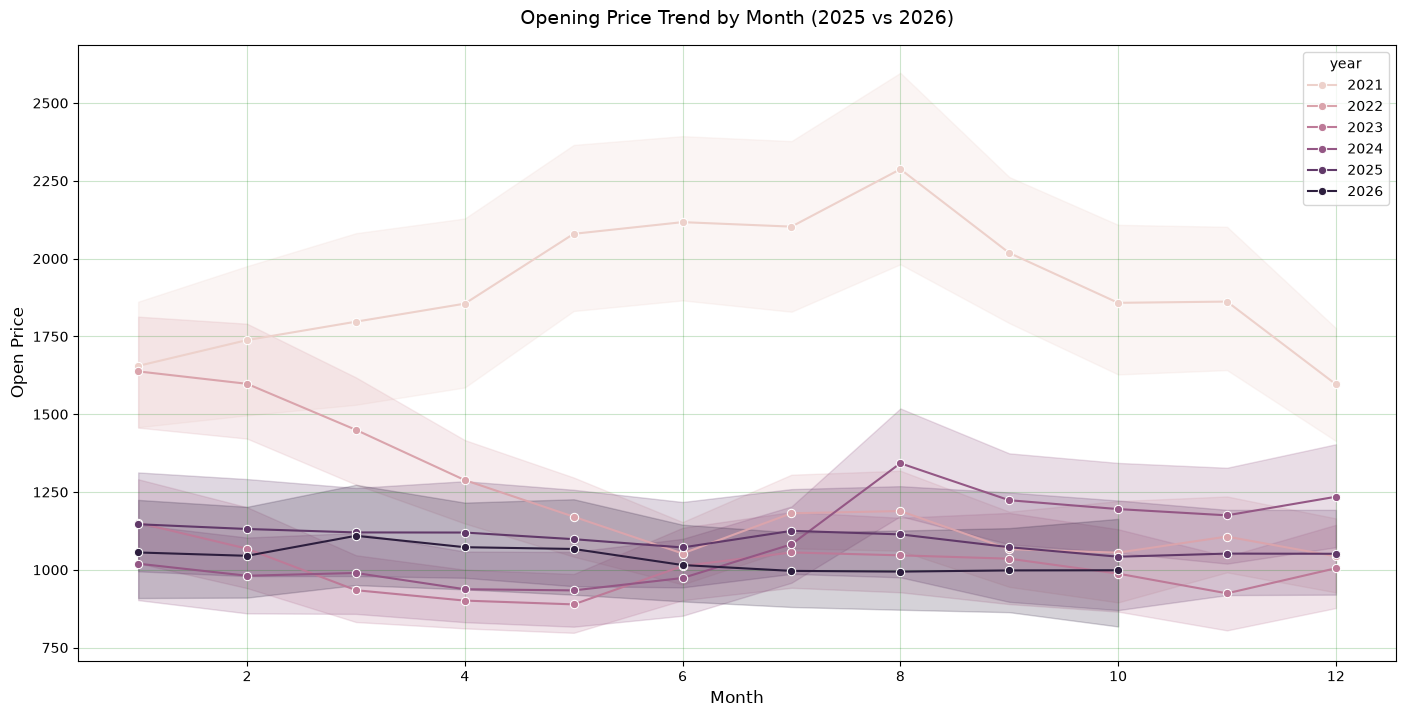

In [44]:

# 1. Properly filter for both years 2025 and 2026 using .isin()
filtered_data = nepse_copy[nepse_copy['year'].isin([2024,2023,2022,2021,2025, 2026])]

# 2. Create the line plot
plt.figure(figsize=(17, 8))
sns.lineplot(
    data=filtered_data,
    x='month',
    y='open',
    hue='year',
    marker='o',  # Optional: adds dots to the lines for clearer data points
)

plt.grid(c='g', alpha=0.2)
plt.title('Opening Price Trend by Month (2025 vs 2026)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Open Price', fontsize=12)

plt.show()

### closing analysis

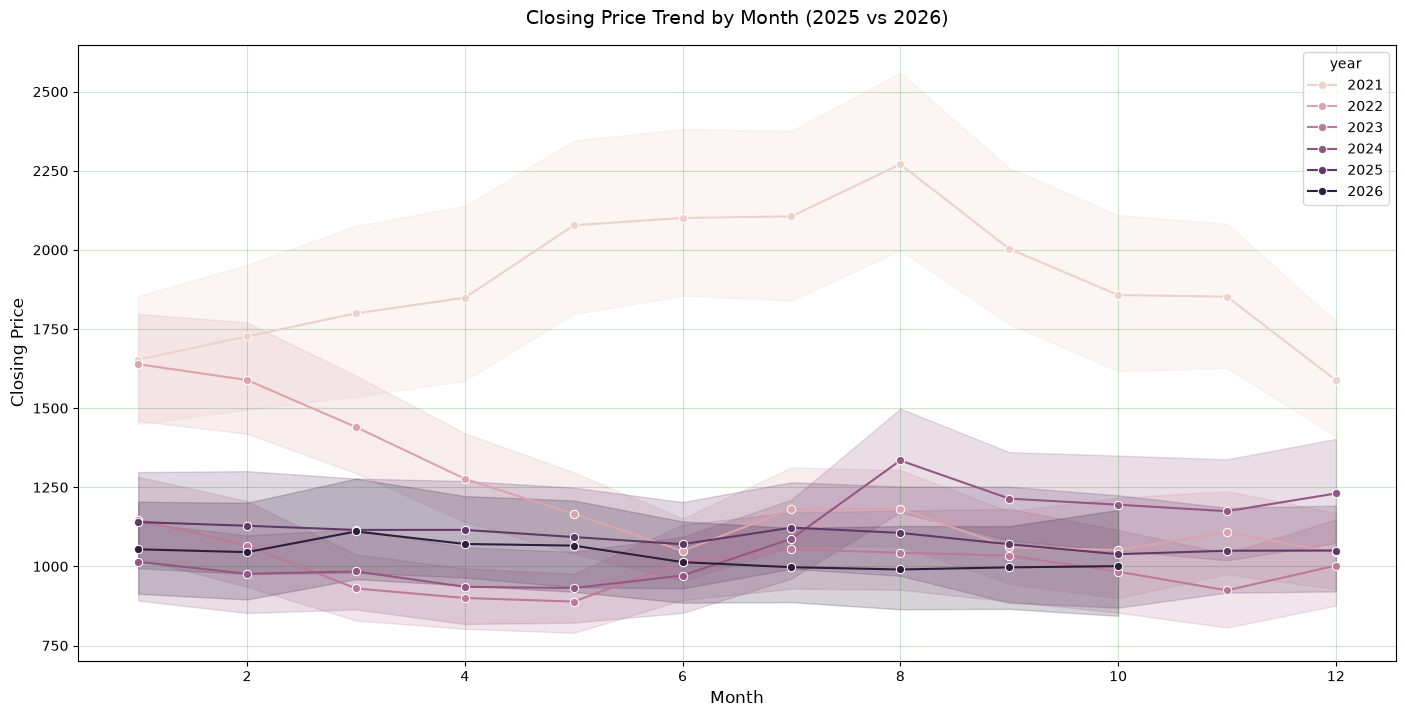

In [43]:
# 1. Properly filter for both years 2025 and 2026 using .isin()
filtered_data = nepse_copy[nepse_copy['year'].isin([2024,2023,2022,2021,2025, 2026])]

# 2. Create the line plot
plt.figure(figsize=(17, 8))
sns.lineplot(
    data=filtered_data,
    x='month',
    y='close',
    hue='year',
    marker='o',  # Optional: adds dots to the lines for clearer data points
)

plt.grid(c='g', alpha=0.2)
plt.title('Closing Price Trend by Month (2025 vs 2026)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Closing Price', fontsize=12)

plt.show()

# T = Transforming Data

## correlation


In [47]:
# correlation
nepse_data.corr(numeric_only=True)

,open,high,low,close,per_change,traded_quantity,traded_amount,status
open,1.000000,0.999523,0.999662,0.999392,-0.001947,-0.175197,0.043583,0.012714
high,0.999523,1.000000,0.999501,0.999724,0.011094,-0.173396,0.047216,0.017943
low,0.999662,0.999501,1.000000,0.999694,0.008207,-0.176572,0.041144,0.016867
close,0.999392,0.999724,0.999694,1.000000,0.016437,-0.175039,0.044481,0.022173
per_change,-0.001947,0.011094,0.008207,0.016437,1.000000,0.070910,0.079374,0.370460
traded_quantity,-0.175197,-0.173396,-0.176572,-0.175039,0.070910,1.000000,0.735779,0.025065
traded_amount,0.043583,0.047216,0.041144,0.044481,0.079374,0.735779,1.000000,0.035919
status,0.012714,0.017943,0.016867,0.022173,0.370460,0.025065,0.035919,1.000000


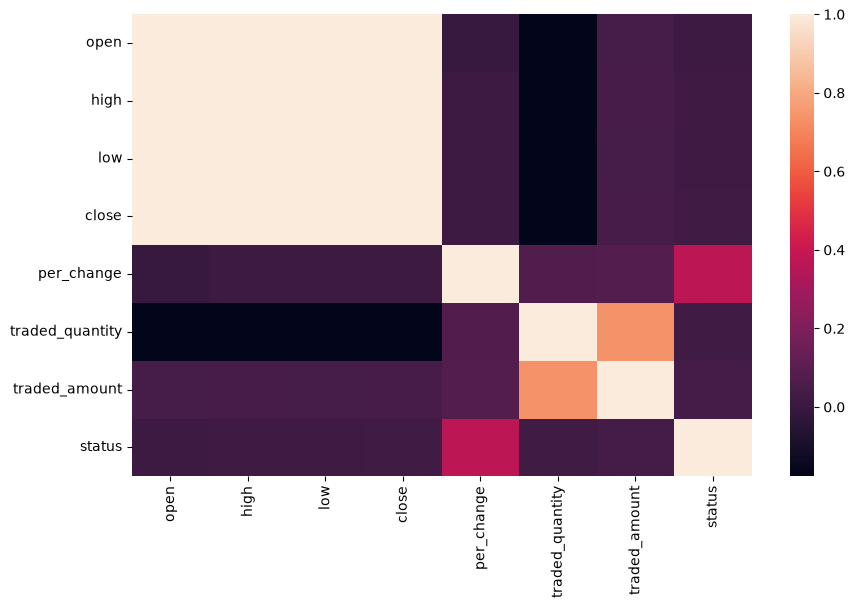

In [56]:
plt.figure(figsize=(10, 6))
sns.heatmap(nepse_data.corr(numeric_only=True))
plt.show()

## MACD INDICATOR column

In [59]:
# 1. Calculate the 12-period and 26-period EMAs of the Closing price
ema_12 = nepse_copy['close'].ewm(span=12, adjust=False).mean()
ema_26 = nepse_copy['close'].ewm(span=26, adjust=False).mean()

# 2. Compute the MACD Line
nepse_copy['macd'] = ema_12 - ema_26

# 3. Compute the Signal Line (9-period EMA of the MACD Line)
nepse_copy['macd_signal'] = nepse_copy['macd'].ewm(span=9, adjust=False).mean()

# 4. Compute the Histogram
nepse_copy['macd_histogram'] = nepse_copy['macd'] - nepse_copy['macd_signal']

### amount strength multiplier

In [69]:
# 1. Calculate the 20-day moving average of traded amount
nepse_copy['amount_sma20'] = nepse_copy['traded_amount'].rolling(window=20).mean()

# 2. Calculate Turnover Strength Multiplier
nepse_copy['strength_multiplier'] = nepse_copy['traded_amount'] / nepse_copy['amount_sma20']

In [70]:
nepse_copy

,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day,macd,macd_signal,macd_histogram,amount_sma20,strength_multiplier
0,1091.0,1155.0,1112.0,1155.0,NaN,38.0,43057.0,0,NABIL,2011,5,15,0.000000,0.000000,0.000000,NaN,NaN
1,1155.0,1193.0,1160.0,1193.0,3.29,156.0,183026.0,0,NABIL,2011,5,16,3.031339,0.606268,2.425071,NaN,NaN
2,1193.0,1172.0,1150.0,1172.0,-1.76,939.0,1087972.0,0,NABIL,2011,5,18,3.696561,1.224326,2.472234,NaN,NaN
3,1172.0,1194.0,1155.0,1194.0,1.88,490.0,573992.0,0,NABIL,2011,5,19,5.930606,2.165582,3.765024,NaN,NaN
4,1194.0,1193.0,1178.0,1178.0,-1.34,115.0,135930.0,0,NABIL,2011,5,22,6.336987,2.999863,3.337124,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58530,230.0,238.0,230.0,236.2,2.25,1068987.0,251983049.4,1,KBL,2026,10,12,3.736196,2.814293,0.921902,1.038684e+08,2.425983
58531,236.0,240.7,235.0,237.3,0.47,1064554.0,253783078.3,1,KBL,2026,10,13,4.266298,3.104694,1.161604,1.151858e+08,2.203249
58532,237.0,243.0,235.6,241.6,1.81,1103357.0,264645143.4,1,KBL,2026,10,14,4.976022,3.478960,1.497062,1.265215e+08,2.091701
58533,242.0,246.0,237.0,238.0,-1.49,977963.0,236131026.8,-1,KBL,2026,10,15,5.188187,3.820805,1.367382,1.364821e+08,1.730124


In [71]:
nepse_copy.isna().sum()

open                      0
high                      0
low                       0
close                     0
per_change               14
traded_quantity           0
traded_amount             0
status                    0
Company                   0
year                      0
month                     0
day                       0
macd                      0
macd_signal               0
macd_histogram            0
amount_sma20             19
strength_multiplier    2099
dtype: int64

In [ ]:


# 1. Create chronological ordering date and sort
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date'])

# 2. Vectorized calculation of EMAs per company using groupby transform
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# 3. Volume Strength Filter (min_periods=1 prevents NaNs)
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# 4. Signal Generation & Daily Returns
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

nepse_copy['daily_return'] = nepse_copy.groupby('Company')['close'].pct_change().fillna(0.0)

# Strategy return: yesterday's signal * today's return
nepse_copy['strategy_return'] = nepse_copy.groupby('Company')['signal'].shift(1).fillna(0) * nepse_copy['daily_return']

# 5. Cumulative growth factor per company
nepse_copy['cumulative_growth'] = nepse_copy.groupby('Company')['strategy_return'].transform(lambda x: (1.0 + x).cumprod())
nepse_copy['cumulative_growth'] = nepse_copy['cumulative_growth'].replace([np.inf, -np.inf], np.nan).fillna(1.0)

# 6. Select top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()

# Drop duplicate rows for the same company on the same date (keeps the last entry)
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Pivot table safely
growth_pivot = portfolio_subset.pivot(index='temp_date', columns='Company', values='cumulative_growth')
growth_pivot = growth_pivot.ffill().fillna(1.0)

# 7. Portfolio Simulation: NPR 200,000 total -> NPR 10,000 per company
initial_capital_per_stock = 10000 
portfolio_values = growth_pivot * initial_capital_per_stock
total_portfolio_value = portfolio_values.sum(axis=1)

# Results
start_value = total_portfolio_value.iloc[0]
final_value = total_portfolio_value.iloc[-1]

print(f"Initial Portfolio Investment (2015): NPR {start_value:,.2f}")
print(f"Predicted Portfolio Value (2026): NPR {final_value:,.2f}")
print(f"Total Return Multiplier: {final_value / start_value:.2f}x")

Initial Portfolio Investment (2015): NPR 200,000.00
Predicted Portfolio Value (2026): NPR 617,504.00
Total Return Multiplier: 3.09x


In [78]:
nepse_copy.head(10)

,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,...,macd_histogram,amount_sma20,strength_multiplier,temp_date,vol_sma20,vol_strength,signal,daily_return,strategy_return,cumulative_growth
7896,117.0,122.0,116.0,120.0,NaN,5280.0,0.0,0,ADBL,2010,...,-4.059313,3.588790e+07,0.0,2010-09-16,5280.000000,1.000000,0,0.000000,0.0,1.0
7897,120.0,120.0,116.0,118.0,-1.67,2648.0,0.0,0,ADBL,2010,...,-7.288731,3.527997e+07,0.0,2010-09-19,3964.000000,0.668012,0,-0.016667,-0.0,1.0
7898,118.0,119.0,116.0,118.0,0.00,2346.0,0.0,0,ADBL,2010,...,-8.918351,3.283717e+07,0.0,2010-09-20,3424.666667,0.685030,0,0.000000,0.0,1.0
7899,118.0,118.0,115.0,116.0,-1.69,7160.0,0.0,0,ADBL,2010,...,-9.567129,3.053330e+07,0.0,2010-09-21,4358.500000,1.642767,0,-0.016949,-0.0,1.0
7900,116.0,120.0,117.0,120.0,3.45,8417.0,0.0,0,ADBL,2010,...,-9.162414,2.875369e+07,0.0,2010-09-23,5170.200000,1.627983,0,0.034483,0.0,1.0
7901,120.0,122.0,117.0,121.0,0.83,9541.0,0.0,0,ADBL,2010,...,-8.289174,2.769244e+07,0.0,2010-09-26,5898.666667,1.617484,0,0.008333,0.0,1.0
7902,121.0,122.0,116.0,119.0,-1.65,10433.0,0.0,0,ADBL,2010,...,-7.340610,2.676284e+07,0.0,2010-09-27,6546.428571,1.593693,0,-0.016529,-0.0,1.0
7903,119.0,120.0,119.0,119.0,0.00,2682.0,0.0,0,ADBL,2010,...,-6.250194,2.566535e+07,0.0,2010-09-28,6063.375000,0.442328,0,0.000000,0.0,1.0
7904,119.0,120.0,117.0,119.0,0.00,2561.0,0.0,0,ADBL,2010,...,-5.113782,2.513901e+07,0.0,2010-09-29,5674.222222,0.451339,0,0.000000,0.0,1.0
7905,119.0,120.0,117.0,119.0,0.00,1912.0,0.0,0,ADBL,2010,...,-3.996460,2.408859e+07,0.0,2010-09-30,5298.000000,0.360891,0,0.000000,0.0,1.0


In [79]:
import pandas as pd
import numpy as np

# 1. Create chronological ordering date and sort
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date'])

# 2. Vectorized calculation of EMAs per company using groupby transform
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# 3. Volume Strength Filter (min_periods=1 prevents NaNs)
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# 4. Signal Generation & Daily Returns
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

nepse_copy['daily_return'] = nepse_copy.groupby('Company')['close'].pct_change().fillna(0.0)

# Strategy return: yesterday's signal * today's return
nepse_copy['strategy_return'] = nepse_copy.groupby('Company')['signal'].shift(1).fillna(0) * nepse_copy['daily_return']

# 5. Cumulative growth factor per company
nepse_copy['cumulative_growth'] = nepse_copy.groupby('Company')['strategy_return'].transform(lambda x: (1.0 + x).cumprod())
nepse_copy['cumulative_growth'] = nepse_copy['cumulative_growth'].replace([np.inf, -np.inf], np.nan).fillna(1.0)

# 6. Select top 20 companies and clean duplicates
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Pivot table safely
growth_pivot = portfolio_subset.pivot(index='temp_date', columns='Company', values='cumulative_growth')
growth_pivot = growth_pivot.ffill().fillna(1.0)

# 7. Portfolio Simulation: NPR 200,000 total -> NPR 10,000 per company
initial_capital_per_stock = 10000 
company_portfolio_values = growth_pivot * initial_capital_per_stock

# --- INDIVIDUAL COMPANY PERFORMANCE REPORT ---
summary_list = []
for company in growth_pivot.columns:
    comp_series = company_portfolio_values[company].dropna()
    if len(comp_series) > 0:
        start_val = comp_series.iloc[0]
        final_val = comp_series.iloc[-1]
        multiplier = final_val / start_val if start_val > 0 else 1.0
        summary_list.append({
            'Company': company,
            'Initial (NPR)': start_val,
            'Predicted 2026 (NPR)': final_val,
            'Multiplier': multiplier
        })

summary_df = pd.DataFrame(summary_list)
print("--- Per-Company Backtest Performance Report (2015 - 2026) ---")
print(summary_df.to_string(index=False))
print("\n" + "="*60 + "\n")

# --- COMBINED PORTFOLIO SUMMARY ---
total_portfolio_value = company_portfolio_values.sum(axis=1)
total_start = total_portfolio_value.iloc[0]
total_final = total_portfolio_value.iloc[-1]

print(f"Total Initial Portfolio Investment (2015): NPR {total_start:,.2f}")
print(f"Total Predicted Portfolio Value (2026): NPR {total_final:,.2f}")
print(f"Overall Portfolio Return Multiplier: {total_final / total_start:.2f}x")

--- Per-Company Backtest Performance Report (2015 - 2026) ---
Company  Initial (NPR)  Predicted 2026 (NPR)  Multiplier
   ADBL        10000.0          19080.520921    1.908052
   AHPC        10000.0          72652.387851    7.265239
    BBC        10000.0          40175.512164    4.017551
   CHCL        10000.0           4398.105658    0.439811
    CIT        10000.0          79314.493203    7.931449
  CZBIL        10000.0          14786.024979    1.478602
    EBL        10000.0           7347.167808    0.734717
  GBIME        10000.0          20201.968742    2.020197
    HDL        10000.0          34191.342898    3.419134
    KBL        10000.0          31409.277193    3.140928
   LICN        10000.0          52235.310740    5.223531
  NABIL        10000.0          13431.408777    1.343141
    NFS        10000.0          31551.436152    3.155144
   NIMB        10000.0          11330.720173    1.133072
   NLIC        10000.0          22892.046097    2.289205
    NTC        10000.0    